<a href="https://colab.research.google.com/github/apatel4746/stockfrauddetection/blob/stock-analysis/stockfraud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q yfinance

Load the stock market data and create the dataframes for comtech and pfizer

In [ ]:
import yfinance as yf
import pandas as pd
#info trade November 2021
pfe=yf.download(
    "PFE",
    start="2020-01-01",
    end="2022-01-01",
    auto_adjust=False,
    progress=False
    )

#insider trading March 2024
cmtl=yf.download(
    "CMTL",
    start="2022-01-01",
    end="2024-05-01",
    auto_adjust=False,
    progress=False
    )

print("Pfizer", pfe.shape)
print("Comtech:", cmtl.shape)
#no parentheses because .shape is attribute not method

Pfizer (505, 6)
Comtech: (584, 6)


Section 1: Discovery

Get basic information about Comtech and Pfizer data

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns', None)
display(pfe.head())
display(cmtl.head())

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,PFE,PFE,PFE,PFE,PFE,PFE
Date,,,,,,
2020-01-02,26.583315,37.134724,37.333965,36.888046,37.286530,16514072
2020-01-03,26.440691,36.935486,37.229603,36.688805,36.736244,14922848
2020-01-06,26.406729,36.888046,37.001900,36.717270,36.831120,15771951
2020-01-07,26.318436,36.764706,37.125237,36.698292,37.115749,20108107
2020-01-08,26.528986,37.058823,37.210625,36.764706,36.774193,16403507


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,CMTL,CMTL,CMTL,CMTL,CMTL,CMTL
Date,,,,,,
2022-01-03,23.037033,23.959999,24.330000,23.760000,23.879999,220400
2022-01-04,22.748587,23.660000,24.299999,23.360001,23.900000,148400
2022-01-05,22.623594,23.530001,24.070000,23.520000,23.660000,103000
2022-01-06,22.652439,23.559999,23.959999,23.290001,23.959999,89200
2022-01-07,22.662052,23.570000,23.799999,23.049999,23.520000,146200


For Comtech and Pfizer Data


1.   Display first 10 rows
2.   get infomration about dataset-- number of null valus in each column, datatype of each value in specific column



1.   Get descriptive statistics about the data
2.   Get size of the dataframe





Comtech

In [ ]:
#display first 10 rows of Comtech data
cmtl.head(10)

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,CMTL,CMTL,CMTL,CMTL,CMTL,CMTL
Date,,,,,,
2022-01-03,23.037033,23.959999,24.330000,23.760000,23.879999,220400
2022-01-04,22.748587,23.660000,24.299999,23.360001,23.900000,148400
2022-01-05,22.623594,23.530001,24.070000,23.520000,23.660000,103000
2022-01-06,22.652439,23.559999,23.959999,23.290001,23.959999,89200
2022-01-07,22.662052,23.570000,23.799999,23.049999,23.520000,146200
2022-01-10,22.287075,23.180000,23.440001,23.010000,23.410000,90600
2022-01-11,22.373610,23.270000,23.360001,22.700001,23.290001,75900
2022-01-12,22.296692,23.190001,23.670000,22.900000,23.360001,118600


In [ ]:
#get information about number of non null values and data types of each column
cmtl.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 584 entries, 2022-01-03 to 2024-04-30
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Adj Close, CMTL)  584 non-null    float64
 1   (Close, CMTL)      584 non-null    float64
 2   (High, CMTL)       584 non-null    float64
 3   (Low, CMTL)        584 non-null    float64
 4   (Open, CMTL)       584 non-null    float64
 5   (Volume, CMTL)     584 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 31.9 KB


In [ ]:
#Get descriptive statitics of Comtech data
cmtl.describe()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,CMTL,CMTL,CMTL,CMTL,CMTL,CMTL
count,584.000000,584.000000,584.000000,584.000000,584.000000,5.840000e+02
mean,11.226556,11.373510,11.651164,11.136147,11.409897,2.435437e+05
std,3.988884,4.151908,4.209894,4.095166,4.155706,3.792713e+05
min,1.580000,1.580000,1.750000,1.530000,1.580000,2.240000e+04
25%,8.993451,9.135000,9.340000,8.945000,9.107500,1.002250e+05
50%,11.108028,11.190000,11.465000,10.905000,11.230000,1.415000e+05
75%,12.571502,12.697500,13.032500,12.435000,12.717500,2.464000e+05
max,23.037033,23.959999,24.330000,23.760000,23.959999,6.527500e+06


In [ ]:
#Get size of Comtech dataframe
cmtl.shape

(584, 6)

Pfizer

In [ ]:
pfe.head(10)

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,PFE,PFE,PFE,PFE,PFE,PFE
Date,,,,,,
2020-01-02,26.583315,37.134724,37.333965,36.888046,37.286530,16514072
2020-01-03,26.440691,36.935486,37.229603,36.688805,36.736244,14922848
2020-01-06,26.406729,36.888046,37.001900,36.717270,36.831120,15771951
2020-01-07,26.318436,36.764706,37.125237,36.698292,37.115749,20108107
2020-01-08,26.528986,37.058823,37.210625,36.764706,36.774193,16403507
2020-01-09,26.413519,36.897533,37.258064,36.802658,37.258064,21971895
2020-01-10,26.821039,37.466793,37.599621,36.973434,36.982922,21557357
2020-01-13,26.766701,37.390892,37.732449,37.201138,37.590134,15392405


In [ ]:
pfe.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 505 entries, 2020-01-02 to 2021-12-31
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   (Adj Close, PFE)  505 non-null    float64
 1   (Close, PFE)      505 non-null    float64
 2   (High, PFE)       505 non-null    float64
 3   (Low, PFE)        505 non-null    float64
 4   (Open, PFE)       505 non-null    float64
 5   (Volume, PFE)     505 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 27.6 KB


In [ ]:
pfe.describe()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,PFE,PFE,PFE,PFE,PFE,PFE
count,505.000000,505.000000,505.000000,505.000000,505.000000,5.050000e+02
mean,28.859698,38.546978,38.985582,38.111763,38.562488,3.343352e+07
std,5.149276,6.070442,6.167766,5.920978,6.016457,1.913345e+07
min,19.547657,27.030361,28.064516,26.451612,27.286528,1.084640e+07
25%,25.736485,34.810246,35.104362,34.520000,34.819733,2.202540e+07
50%,27.115562,36.584438,36.944973,36.242886,36.700001,2.776320e+07
75%,30.508940,40.150002,40.669998,39.910000,40.209999,3.847120e+07
max,47.423313,61.250000,61.709999,59.830002,60.599998,2.301539e+08


In [ ]:
pfe.shape

(505, 6)

Verify the dataframes for both Pfizer and Cometech are indexed by date and the date format

In [ ]:
print(pfe.index)
print(cmtl.index)

DatetimeIndex(['2020-01-02', '2020-01-03', '2020-01-06', '2020-01-07',
               '2020-01-08', '2020-01-09', '2020-01-10', '2020-01-13',
               '2020-01-14', '2020-01-15',
               ...
               '2021-12-17', '2021-12-20', '2021-12-21', '2021-12-22',
               '2021-12-23', '2021-12-27', '2021-12-28', '2021-12-29',
               '2021-12-30', '2021-12-31'],
              dtype='datetime64[ns]', name='Date', length=505, freq=None)
DatetimeIndex(['2022-01-03', '2022-01-04', '2022-01-05', '2022-01-06',
               '2022-01-07', '2022-01-10', '2022-01-11', '2022-01-12',
               '2022-01-13', '2022-01-14',
               ...
               '2024-04-17', '2024-04-18', '2024-04-19', '2024-04-22',
               '2024-04-23', '2024-04-24', '2024-04-25', '2024-04-26',
               '2024-04-29', '2024-04-30'],
              dtype='datetime64[ns]', name='Date', length=584, freq=None)


Check order of the dates-- if they never decrease

In [ ]:
print(pfe.index.is_monotonic_increasing)
print(cmtl.index.is_monotonic_increasing)

True
True


In [ ]:
cmtl.columns


MultiIndex([('Adj Close', 'CMTL'),
            (    'Close', 'CMTL'),
            (     'High', 'CMTL'),
            (      'Low', 'CMTL'),
            (     'Open', 'CMTL'),
            (   'Volume', 'CMTL')],
           names=['Price', 'Ticker'])

In [ ]:
pfe.columns

MultiIndex([('Adj Close', 'PFE'),
            (    'Close', 'PFE'),
            (     'High', 'PFE'),
            (      'Low', 'PFE'),
            (     'Open', 'PFE'),
            (   'Volume', 'PFE')],
           names=['Price', 'Ticker'])

In [ ]:
cmtl.columns=cmtl.columns.get_level_values(0)
pfe.columns=pfe.columns.get_level_values(0)

Rename columns in both dataframes so it is easier to read

In [ ]:
cmtl=cmtl.rename(columns={'Adj Close': 'adj_close', 'Close': 'close', 'High': 'high', 'Low': 'low', 'Open': 'open', 'Volume': 'volume'})
cmtl.columns

Index(['adj_close', 'close', 'high', 'low', 'open', 'volume'], dtype='object', name='Price')

In [ ]:
pfe=pfe.rename(columns={'Adj Close': 'adj_close', 'Close': 'close', 'High': 'high', 'Low': 'low', 'Open': 'open', 'Volume': 'volume'})
pfe.columns

Index(['adj_close', 'close', 'high', 'low', 'open', 'volume'], dtype='object', name='Price')

Check missing data for comtech and pfizer

In [ ]:
cmtl.isna().sum()

,0
Price,
adj_close,0
close,0
high,0
low,0
open,0
volume,0


In [ ]:
pfe.isna().sum()

,0
Price,
adj_close,0
close,0
high,0
low,0
open,0
volume,0


Check duplicated data for comtech and pfizer

In [ ]:
duplicates_cmtl=cmtl.duplicated().sum()

percentage_cmtl=cmtl.duplicated().sum() / cmtl.shape[0]*100
print(f'{duplicates_cmtl} rows contain duplicates amounting to {percentage_cmtl.round(2)}')

0 rows contain duplicates amounting to 0.0


In [ ]:
duplicates_pfe=pfe.duplicated().sum()

percentage_pfe=pfe.duplicated().sum() / pfe.shape[0]*100
print(f'{duplicates_pfe} rows contain duplicates amounting to {percentage_pfe.round(2)}')

0 rows contain duplicates amounting to 0.0


In [ ]:
cmtl.describe()

Price,adj_close,close,high,low,open,volume
count,584.000000,584.000000,584.000000,584.000000,584.000000,5.840000e+02
mean,11.226556,11.373510,11.651164,11.136147,11.409897,2.435437e+05
std,3.988884,4.151908,4.209894,4.095166,4.155706,3.792713e+05
min,1.580000,1.580000,1.750000,1.530000,1.580000,2.240000e+04
25%,8.993451,9.135000,9.340000,8.945000,9.107500,1.002250e+05
50%,11.108028,11.190000,11.465000,10.905000,11.230000,1.415000e+05
75%,12.571502,12.697500,13.032500,12.435000,12.717500,2.464000e+05
max,23.037033,23.959999,24.330000,23.760000,23.959999,6.527500e+06


In [ ]:
pfe.describe()

Price,adj_close,close,high,low,open,volume
count,505.000000,505.000000,505.000000,505.000000,505.000000,5.050000e+02
mean,28.859698,38.546978,38.985582,38.111763,38.562488,3.343352e+07
std,5.149276,6.070442,6.167766,5.920978,6.016457,1.913345e+07
min,19.547657,27.030361,28.064516,26.451612,27.286528,1.084640e+07
25%,25.736485,34.810246,35.104362,34.520000,34.819733,2.202540e+07
50%,27.115562,36.584438,36.944973,36.242886,36.700001,2.776320e+07
75%,30.508940,40.150002,40.669998,39.910000,40.209999,3.847120e+07
max,47.423313,61.250000,61.709999,59.830002,60.599998,2.301539e+08


Normalize Comtech and Pfizer data

Plot boxplots for Comtech and Pfizer

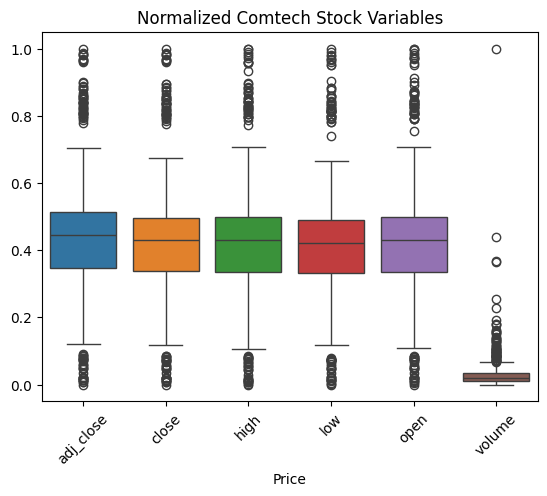

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler=MinMaxScaler()
normalized_data=scaler.fit_transform(cmtl)

df_normalized_cmtl=pd.DataFrame(normalized_data, columns=cmtl.columns, index=cmtl.index)

sns.boxplot(data= df_normalized_cmtl)
plt.xticks(rotation=45)
plt.title("Normalized Comtech Stock Variables")

plt.show()

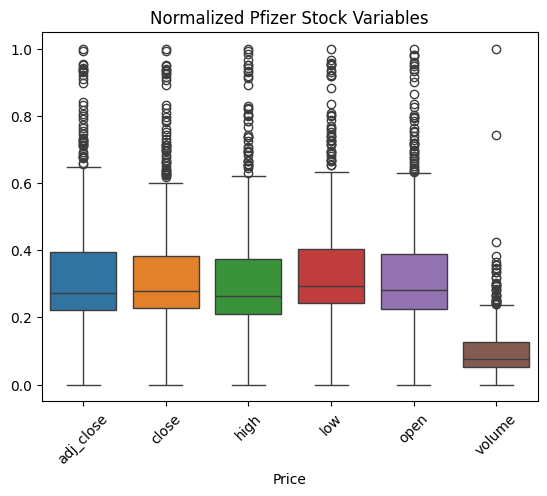

In [ ]:
normalized_data=scaler.fit_transform(pfe)

df_normalized_pfe=pd.DataFrame(normalized_data, columns=pfe.columns, index=pfe.index)

sns.boxplot(data= df_normalized_pfe)
plt.xticks(rotation=45)
plt.title("Normalized Pfizer Stock Variables")

plt.show()

Investigate for outliers in Comtech and Pfizer data

In [ ]:
from numpy._core.defchararray import lower
percentile_25_cmtl=cmtl.quantile(0.25)
percentile_75_cmtl=cmtl.quantile(0.75)
iqr_cmtl=percentile_75_cmtl-percentile_25_cmtl

upper_limit_cmtl=percentile_75_cmtl + 1.5*iqr_cmtl
lower_limit_cmtl=percentile_25_cmtl - 1.5*iqr_cmtl
print("Lower limit: ", lower_limit_cmtl)
print("Upper limit: ", upper_limit_cmtl)

outlier_mask_cmtl= (cmtl< lower_limit_cmtl) | (cmtl > upper_limit_cmtl)#pandas frame containing booleans
outliers_cmtl= cmtl[outlier_mask_cmtl.any(axis=1)]

print("Number of rows in data containing outliers: ",len(outliers_cmtl))


Lower limit:  Price
adj_close         3.626375
close             3.791251
high              3.801251
low               3.710000
open              3.692500
volume      -119037.500000
dtype: float64
Upper limit:  Price
adj_close        17.938578
close            18.041249
high             18.571249
low              17.670001
open             18.132500
volume       465662.500000
dtype: float64
Number of rows in data containing outliers:  114


In [ ]:
percentile_25_pfe=pfe.quantile(0.25)
percentile_75_pfe=pfe.quantile(0.75)
iqr_pfe=percentile_75_pfe-percentile_25_pfe

upper_limit_pfe=percentile_75_pfe + 1.5*iqr_pfe
lower_limit_pfe=percentile_25_pfe - 1.5*iqr_pfe
print("Lower limit: ", lower_limit_pfe)
print("Upper limit: ", upper_limit_pfe)

outlier_mask_pfe= (pfe< lower_limit_pfe) | (pfe > upper_limit_pfe)#pandas frame containing booleans
outliers_pfe= pfe[outlier_mask_pfe.any(axis=1)]

print("Number of rows in data containing outliers: ",len(outliers_pfe))

Lower limit:  Price
adj_close    1.857780e+01
close        2.680061e+01
high         2.675591e+01
low          2.643500e+01
open         2.673433e+01
volume      -2.643300e+06
dtype: float64
Upper limit:  Price
adj_close    3.766762e+01
close        4.815964e+01
high         4.901845e+01
low          4.799500e+01
open         4.829540e+01
volume       6.313990e+07
dtype: float64
Number of rows in data containing outliers:  70


In [ ]:
print("Volume outliers: ", outlier_mask_cmtl["volume"].sum())
print("Close price outliers: ", outlier_mask_cmtl["close"].sum())
print(outlier_mask_cmtl.sum())
volume_outliers_cmtl=cmtl[outlier_mask_cmtl["volume"]]
display(volume_outliers_cmtl)


Volume outliers:  63
Close price outliers:  77
Price
adj_close    77
close        77
high         76
low          77
open         76
volume       63
dtype: int64


Price,adj_close,close,high,low,open,volume
Date,,,,,,
2022-03-11,15.286470,15.83,17.73,15.01,17.379999,655700
2022-07-15,8.974007,9.23,9.78,8.97,9.480000,770300
2022-07-28,11.223824,11.42,11.44,11.06,11.150000,709100
2022-12-09,13.270816,13.37,14.05,13.35,14.000000,562400
2022-12-13,12.973042,13.07,14.14,12.88,13.980000,466100
...,...,...,...,...,...,...
2024-04-24,1.750000,1.75,1.78,1.58,1.580000,1186100
2024-04-25,1.870000,1.87,1.90,1.66,1.700000,718500
2024-04-26,2.050000,2.05,2.06,1.83,1.840000,670200


In [ ]:
print("Volume outliers: ", outlier_mask_pfe["volume"].sum())
print("Close price outliers: ", outlier_mask_pfe["close"].sum())
print(outlier_mask_pfe.sum())
volume_outliers_pfe=pfe[outlier_mask_pfe["volume"]]
display(volume_outliers_pfe)

Volume outliers:  34
Close price outliers:  47
Price
adj_close    39
close        47
high         42
low          41
open         43
volume       34
dtype: int64


Price,adj_close,close,high,low,open,volume
Date,,,,,,
2020-01-28,25.904129,36.185959,37.466793,36.005692,37.305504,70202408
2020-02-28,22.930244,31.707781,32.201138,30.863379,31.774195,66057447
2020-03-11,22.072588,30.521822,32.144215,30.037951,32.030361,65350213
2020-06-01,24.572405,33.643265,33.899429,33.121441,33.681213,76884979
2020-06-11,23.075609,31.593927,33.851994,31.574953,33.776093,63166642
2020-07-01,23.380514,32.011387,32.770397,31.992411,32.770397,73503009
2020-07-22,26.720579,36.584438,36.745731,35.597721,36.271347,90705554
2020-11-09,27.711658,37.191650,39.838711,36.413662,39.715370,230153864
2020-11-10,27.344055,36.698292,38.462997,36.489563,38.377609,80091668


In [ ]:
display(cmtl.loc["2024-03-01": "2024-03-20", ["close", "volume"]])

Price,close,volume
Date,,
2024-03-01,6.60,139300
2024-03-04,6.49,205000
2024-03-05,6.30,141300
2024-03-06,6.15,129400
2024-03-07,6.07,185000
2024-03-08,5.79,283600
2024-03-11,5.73,256800
2024-03-12,5.76,302900
2024-03-13,4.19,2404700


In [ ]:
display(pfe.loc["2021-10-25": "2021-11-12", ["close", "volume"]])

Price,close,volume
Date,,
2021-10-25,43.150002,22846200
2021-10-26,43.560001,29729100
2021-10-27,42.970001,22317500
2021-10-28,43.180000,18023400
2021-10-29,43.740002,30307500
2021-11-01,43.639999,32681500
2021-11-02,45.450001,69248000
2021-11-03,44.820000,44593100
2021-11-04,43.849998,38172500


In [ ]:
print("Comtech duplicate dates: ", cmtl.index.duplicated().sum())
print("Pfizer duplicate dates: ", pfe.index.duplicated().sum())

print("Comtech negative volumes: ", (cmtl["volume"]<0).sum())
print("Pfizer negative volumes: ", (pfe["volume"]<0).sum())

Comtech duplicate dates:  0
Pfizer duplicate dates:  0
Comtech negative volumes:  0
Pfizer negative volumes:  0


Verify the Comtech and Pfizer data follow expected format


*   date format
*   closing prices are nonnegative


*   low price <= high pirce
*   no dates are not in decreasing order


*   No missing values









In [ ]:
for name, df in [("Comtech", cmtl), ("Pfizer", pfe)]:
  print(f"\n{name} Validation")
  print("Date index type: ", type(df.index))#check date format
  print("Nonpositive closing prices: ", (df["close"] <=0).sum()) #check closing prices are nonegative
  print("High below low: ", (df["high"] < df["low"]).sum()) # check hihest recorded price for trading day is not lower than lowest price
  print("Dates sorted: ", df.index.is_monotonic_increasing)#check chronological ordering
  print("Missing values: ", df.isna().sum().sum())#check missing values across every column
  #first .sum() is for single column second is for all columns


Comtech Validation
Date index type:  <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Nonpositive closing prices:  0
High below low:  0
Dates sorted:  True
Missing values:  0

Pfizer Validation
Date index type:  <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Nonpositive closing prices:  0
High below low:  0
Dates sorted:  True
Missing values:  0


For both Comtech and Pfizer

Create boxplots and histograms

Histograms to discern trading volume distribution

Scatterplot of Daily Return vs Trading Volume to display their correlation

Heatmap to display correlation between trading volume, daily return, and closing price

Line plot tracking how trading volume changes overtime

Seasonal Decomposition  to seperate trading volume into estimated trend, seasonal, and residual components to track 5-day trading week patterns

Calculate centered and trailing moving averages to smooth short term fluctuations and identify broader changes in trading activity

STL Decompositon both robust and non robust methods are compared to examine how extreme trading-volume observations influence estimated trends and seasonal patterns

Autocorrelation Analysis both Autocorrelation function and Partial Autocorrelation function are used to investigate relationships between trading volumes across different trading-day lags


Time-Series Visualization: Line plots are used to identify changes in trading volume over time, including periods of elevated trading activity and unusually large spikes.

Seasonal Decomposition: Additive and multiplicative decomposition methods are applied to separate trading volume into estimated trend, seasonal, and residual components. A five-observation period is used to explore potential trading-week patterns.

Moving Averages: Centered and trailing moving averages are calculated to smooth short-term fluctuations and identify broader changes in trading activity.

STL Decomposition: Robust and non-robust STL methods are compared to examine how extreme trading-volume observations influence estimated trends and seasonal patterns.

Autocorrelation Analysis: The Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) are used to investigate relationships between trading volumes across different trading-day lags.

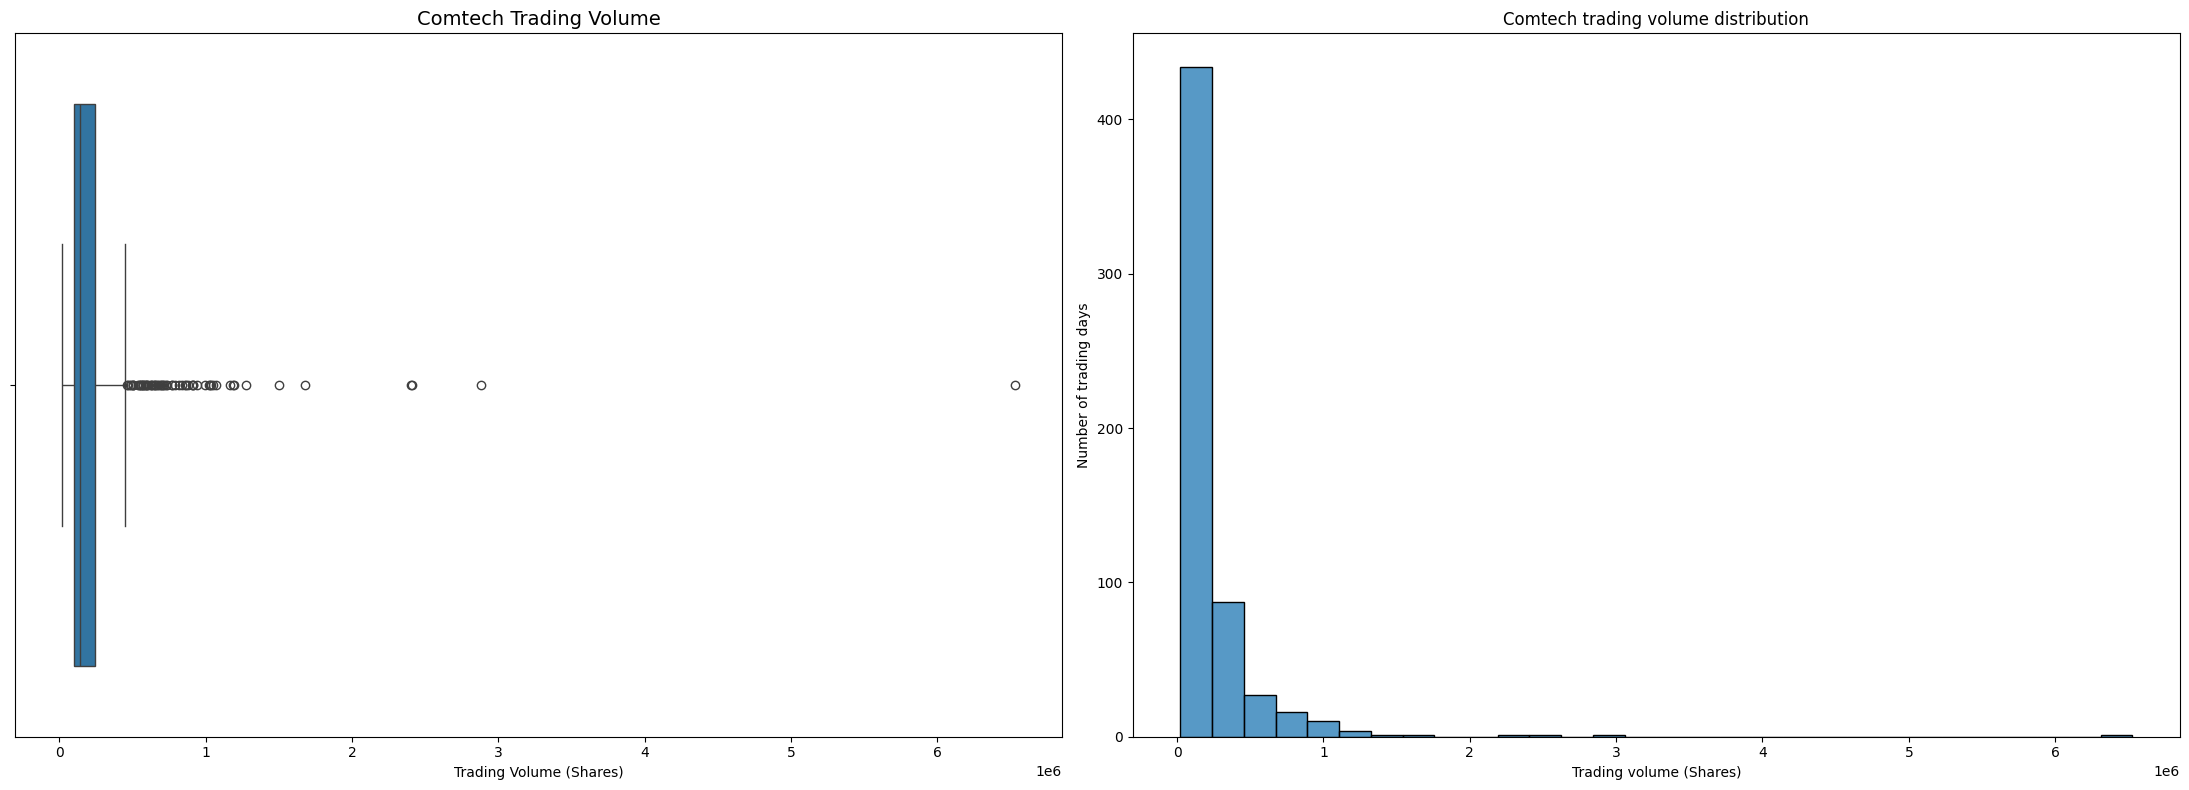

In [ ]:
#set figure and axes
fig, ax = plt.subplots(1,2,figsize=(22,8))

#create boxplot
sns.boxplot(
    data=cmtl,
    x='volume',
    orient="h",
    ax=ax[0]
)


ax[0].set_title('Comtech Trading Volume', fontsize='14')
ax[0].set_xlabel("Trading Volume (Shares)")

#plot histogram showing distribution
sns.histplot(
    data=cmtl,
    x="volume",
    bins=30,
    ax=ax[1]
)

ax[1].set_title('Comtech trading volume distribution')
ax[1].set_xlabel("Trading volume (Shares)")
ax[1].set_ylabel("Number of trading days")
plt.tight_layout()

#display plots
plt.show()

Histograms of the distribution trading volume

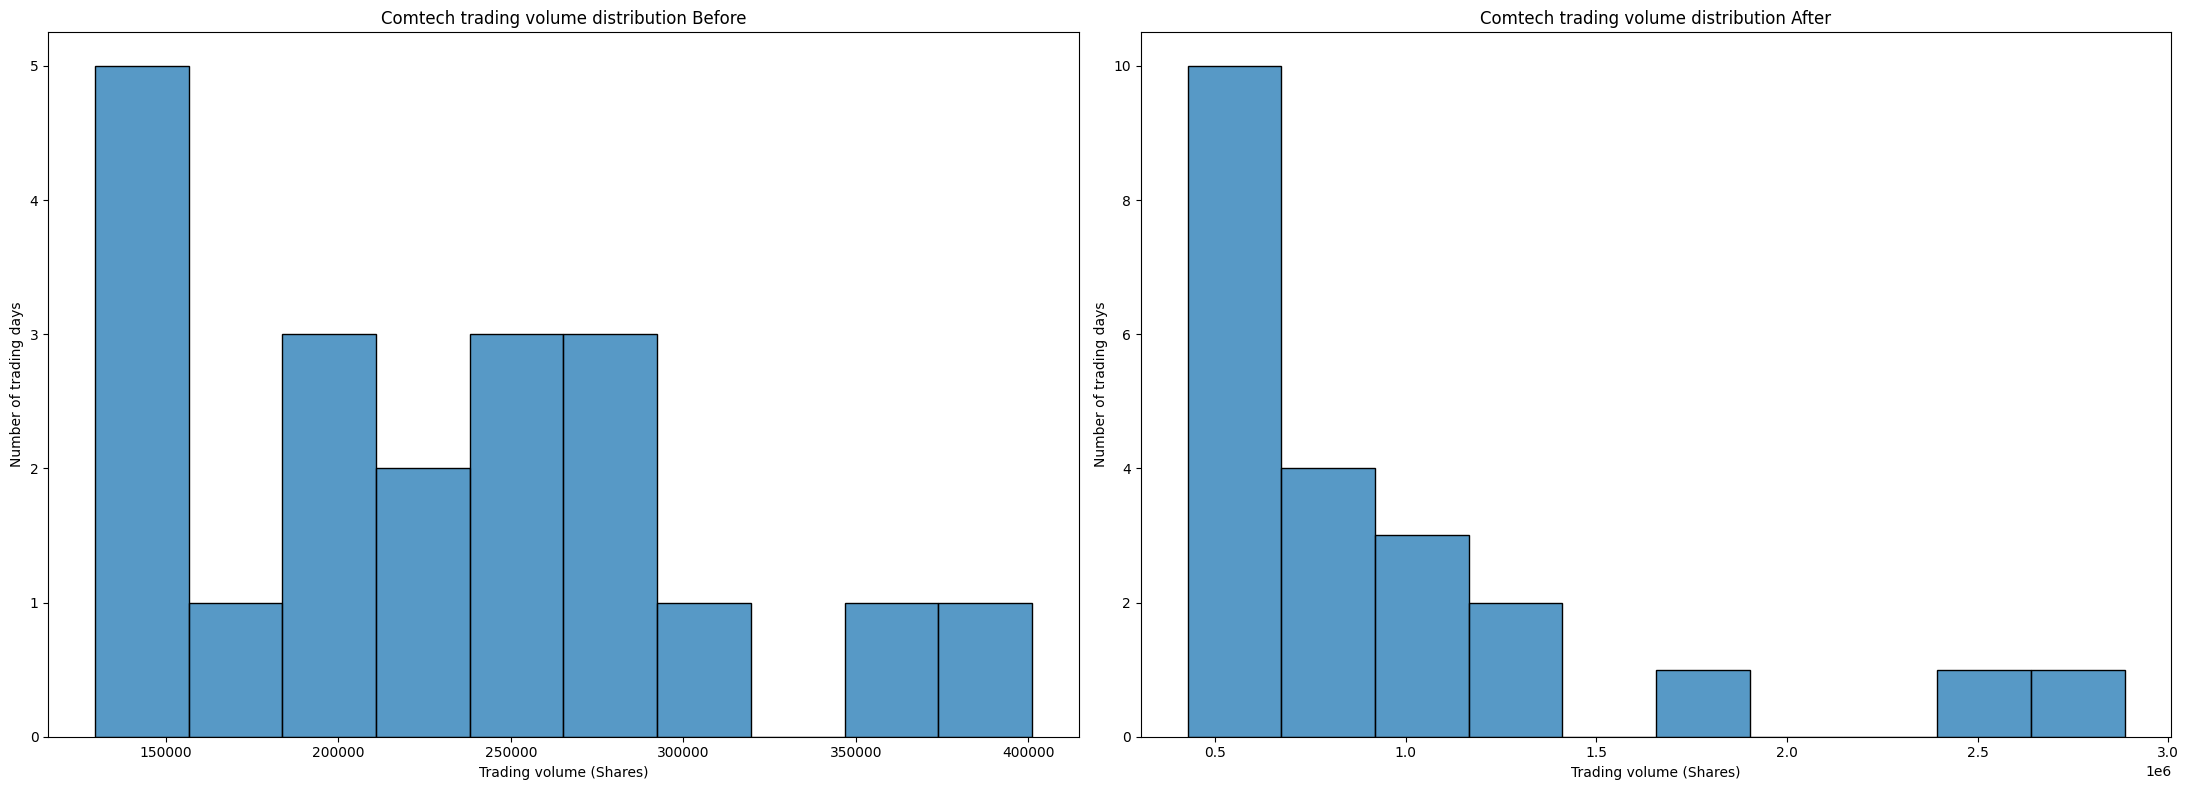

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(22,8))

df_filter1_cmtl= cmtl.loc["2024-02-13" : "2024-03-12"]
df_filter2_cmtl=cmtl.loc["2024-03-13":"2024-04-12"]
sns.histplot(
    data=df_filter1_cmtl,
    x="volume",
    bins=10,
    ax=ax[0]
)

ax[0].set_title('Comtech trading volume distribution Before')
ax[0].set_xlabel("Trading volume (Shares)")
ax[0].set_ylabel("Number of trading days")


sns.histplot(
    data=df_filter2_cmtl,
    x="volume",
    bins=10,
    ax=ax[1]
)

ax[1].set_title('Comtech trading volume distribution After')
ax[1].set_xlabel("Trading volume (Shares)")
ax[1].set_ylabel("Number of trading days")

plt.tight_layout()
plt.show()

In [ ]:
cmtl["daily_return"]=cmtl["close"].pct_change()*100
pfe["daily_return"]=pfe["close"].pct_change()*100

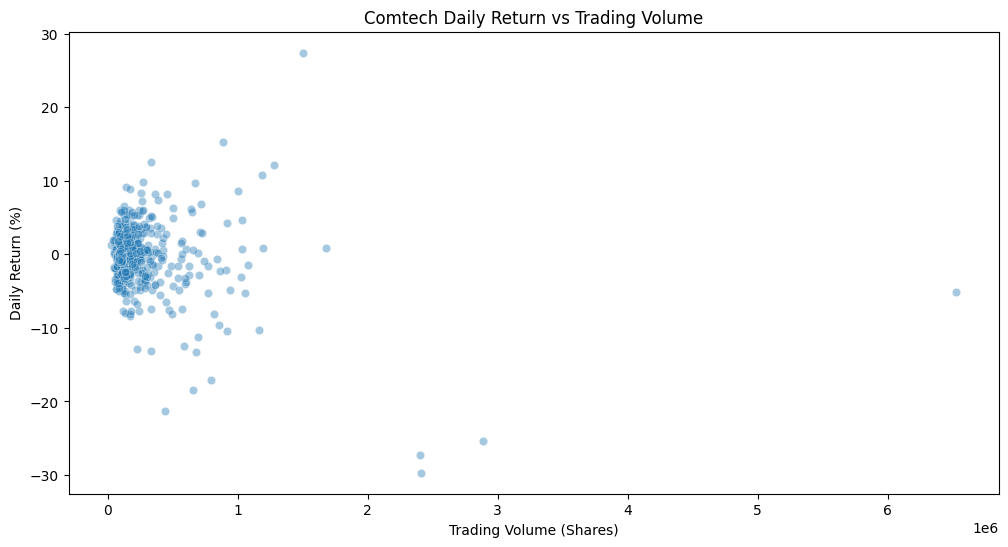

In [ ]:
plt.figure(figsize=(12,6))
sns.scatterplot(
    data=cmtl,
    x="volume",
    y="daily_return",
    alpha=0.4,
)
plt.title("Comtech Daily Return vs Trading Volume")
plt.xlabel("Trading Volume (Shares)")
plt.ylabel("Daily Return (%)")
plt.show()

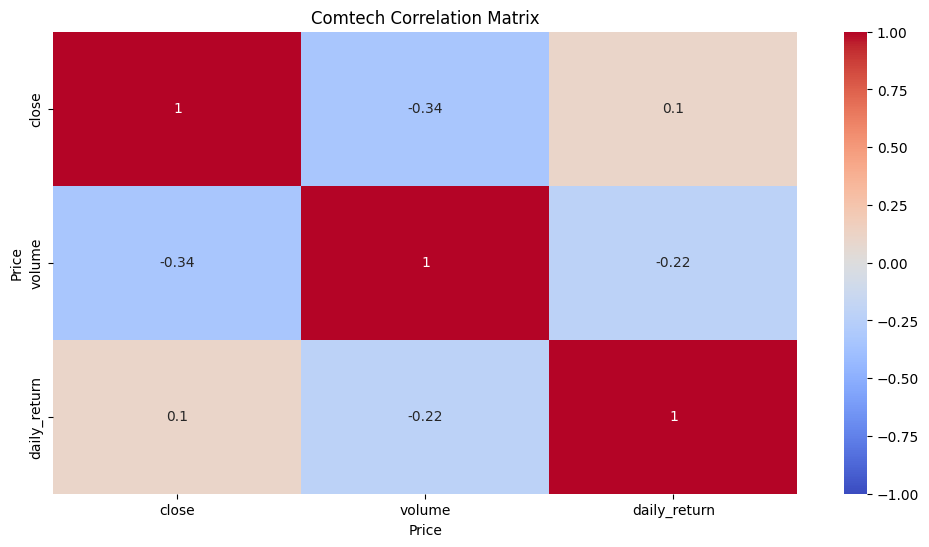

In [ ]:
plt.figure(figsize=(12,6))

corr_matrix=cmtl[["close", "volume", "daily_return"]].corr()
pfe_heatmap=sns.heatmap(
    data=corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Comtech Correlation Matrix")
plt.show()

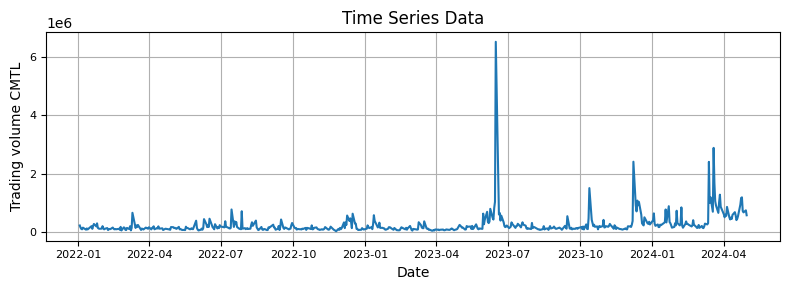

In [ ]:
plt.figure(figsize=(8,3))
plt.plot(cmtl.index,cmtl["volume"])
plt.xlabel('Date', fontsize=10)
plt.ylabel('Trading volume CMTL', fontsize=10)
plt.title('Time Series Data', fontsize=12)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.show()

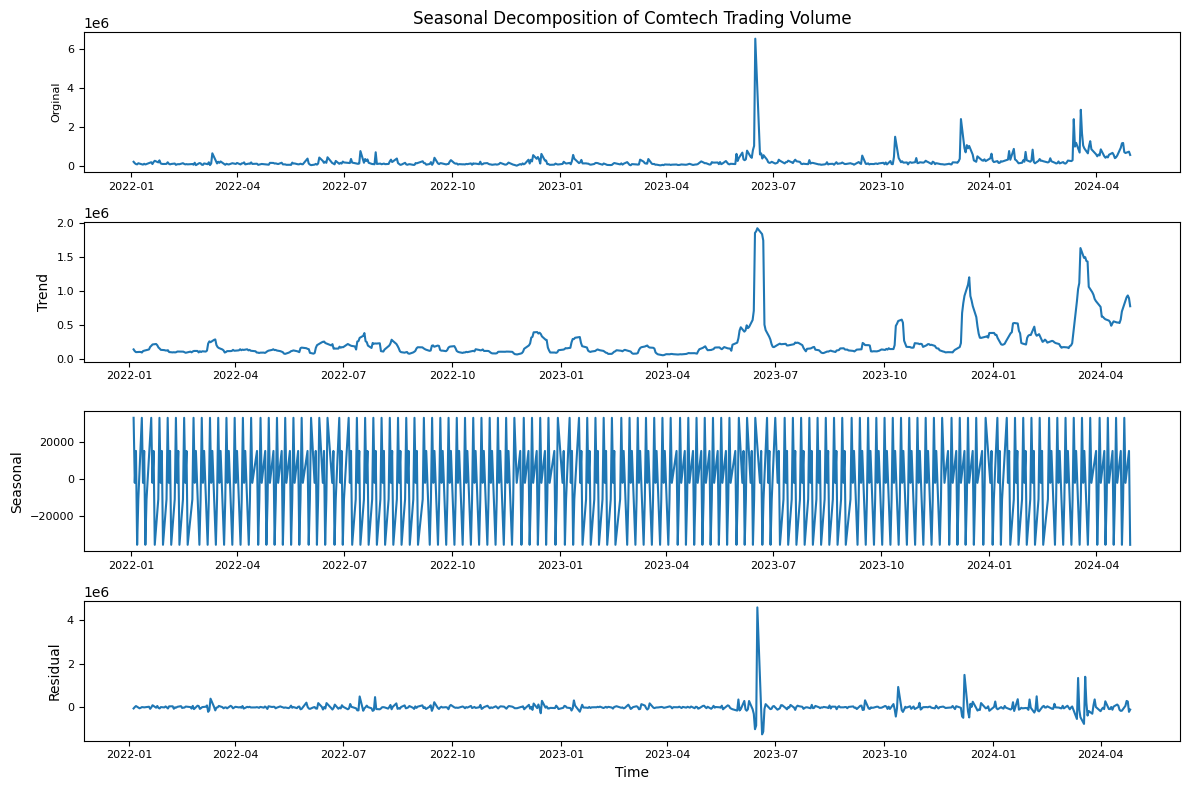

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt
result_cmtl=seasonal_decompose(cmtl["volume"], model="additive", period=5)
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4,1, figsize=(12,8))

ax1.plot(cmtl["volume"])
ax1.set_ylabel('Orginal', fontsize=8)
ax1.set_title('Seasonal Decomposition of Comtech Trading Volume', fontsize=12)

ax2.plot(result_cmtl.trend)
ax2.set_ylabel('Trend', fontsize=10)

ax3.plot(result_cmtl.seasonal)
ax3.set_ylabel('Seasonal', fontsize=10)

ax4.plot(result_cmtl.resid)
ax4.set_xlabel('Time', fontsize=10)
ax4.set_ylabel('Residual', fontsize=10)

for ax in [ax1, ax2, ax3, ax4]:
  ax.tick_params(axis='both', labelsize=8)

plt.tight_layout()
plt.show()

0


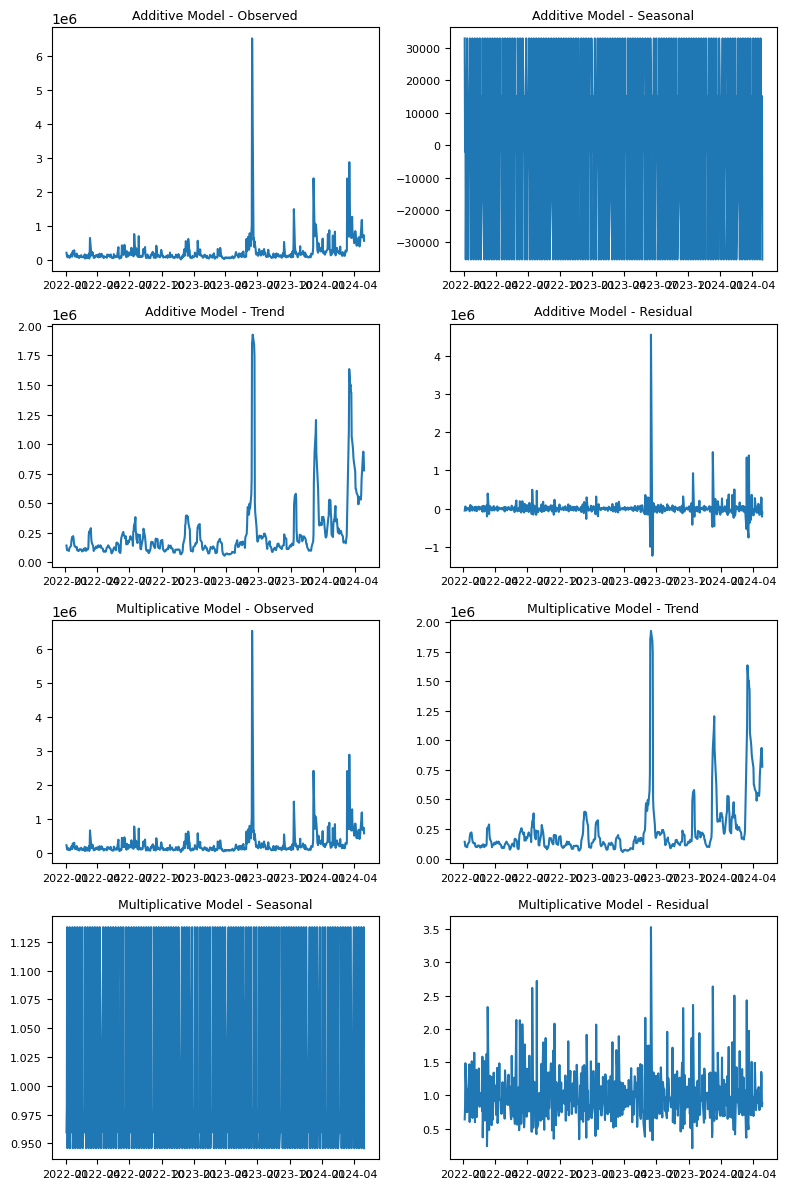

In [ ]:
result_add_cmtl=seasonal_decompose(cmtl["volume"], model='additive', period=5)
print((cmtl["volume"]<=0).sum())
result_mul_cmtl=seasonal_decompose(cmtl["volume"], model='multiplicative', period=5)

fig,axes=plt.subplots(4,2,figsize=(8,12))

axes[0,0].plot(result_add_cmtl.observed)
axes[0,0].set_title('Additive Model - Observed', fontsize=9)

axes[1,0].plot(result_add_cmtl.trend)
axes[1,0].set_title('Additive Model - Trend', fontsize=9)

axes[0,1].plot(result_add_cmtl.seasonal)
axes[0,1].set_title('Additive Model - Seasonal', fontsize=9)

axes[1,1].plot(result_add_cmtl.resid)
axes[1,1].set_title('Additive Model - Residual', fontsize=9)

axes[2,0].plot(result_mul_cmtl.observed)
axes[2,0].set_title('Multiplicative Model - Observed', fontsize=9)

axes[2,1].plot(result_mul_cmtl.trend)
axes[2,1].set_title('Multiplicative Model - Trend', fontsize=9)

axes[3,0].plot(result_mul_cmtl.seasonal)
axes[3,0].set_title('Multiplicative Model - Seasonal', fontsize=9)

axes[3,1].plot(result_mul_cmtl.resid)
axes[3,1].set_title('Multiplicative Model - Residual', fontsize=9)

for ax in axes.flatten():
  ax.tick_params(axis='both', labelsize=8)

plt.tight_layout()
plt.show()

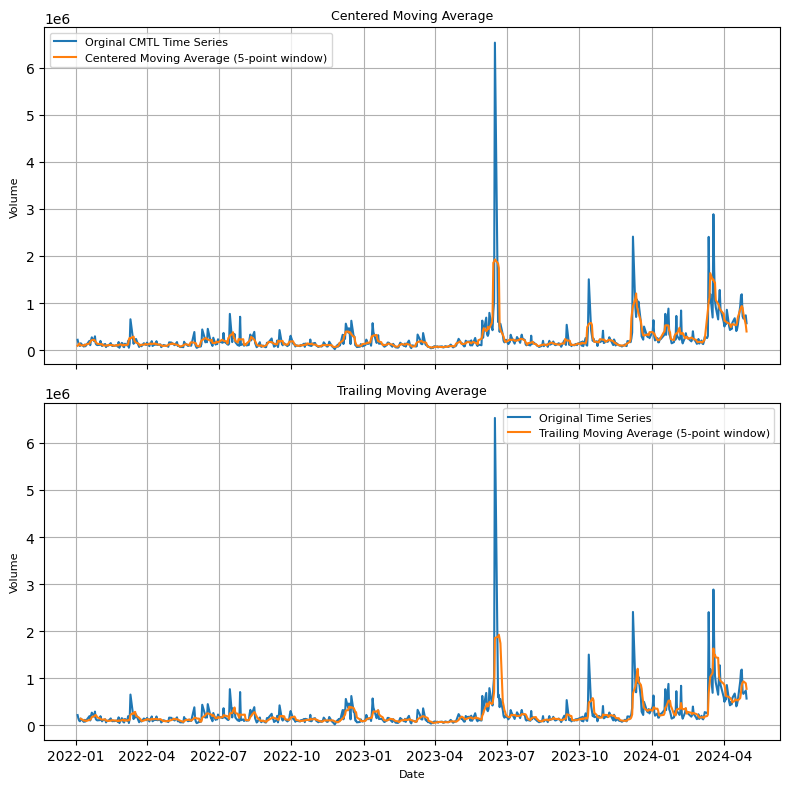

In [ ]:
centered_window_size=5
trailing_window_size=5
centered_ma_cmtl=np.convolve(cmtl["volume"], np.ones(centered_window_size)/centered_window_size, mode='same')
trailing_ma_cmtl=np.convolve(cmtl["volume"], np.ones(trailing_window_size)/trailing_window_size, mode='valid')
residual= cmtl['volume']-centered_ma_cmtl

fig, (ax1, ax2) = plt.subplots(2,1,figsize=(8,8), sharex=True)

ax1.plot(cmtl.index, cmtl["volume"], label="Orginal CMTL Time Series")
ax1.plot(cmtl.index, centered_ma_cmtl, label=f"Centered Moving Average ({centered_window_size}-point window)" )
ax1.set_title("Centered Moving Average", fontsize=9)
ax1.set_ylabel("Volume", fontsize=8)
ax1.legend(fontsize=8)
ax1.grid(True)

ax2.plot(cmtl.index, cmtl["volume"], label="Original Time Series")
ax2.plot(cmtl.index[trailing_window_size-1:], trailing_ma_cmtl, label=f"Trailing Moving Average ({trailing_window_size}-point window)")
ax2.set_title("Trailing Moving Average", fontsize=9)
ax2.set_ylabel("Volume", fontsize=8)
ax2.set_xlabel("Date", fontsize=8)
ax2.legend(fontsize=8)
ax2.grid(True)

plt.tight_layout()
plt.show()

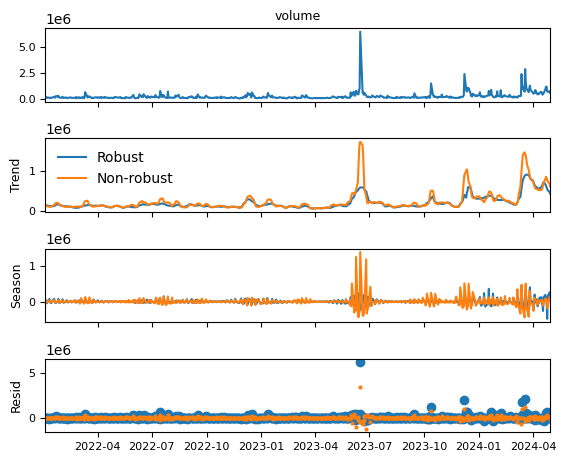

In [ ]:
from statsmodels.tsa.seasonal import STL

def add_stl_plot(fig, res, legend):
  axs=fig.get_axes()
  comps=["trend", "seasonal", "resid"]
  for ax, comp in zip(axs[1:], comps):
    series=getattr(res,comp)
    if comp == "resid":
      ax.plot(series, marker="o", linestyle="none", markersize=2)
    else:
      ax.plot(series)
      if comp=="trend":
        ax.legend(legend, frameon=False)
stl=STL(cmtl["volume"], period=5, robust=True)
res_robust=stl.fit()
fig=res_robust.plot()

for ax in fig.get_axes():
  ax.set_title(ax.get_title(), fontsize=9)
  ax.set_xlabel(ax.get_xlabel(), fontsize=9)
  ax.set_ylabel(ax.get_ylabel(), fontsize=9)
  ax.tick_params(axis='both', labelsize=8)

res_non_robust=STL(cmtl["volume"], period=5, robust=False).fit()
add_stl_plot(fig, res_non_robust, ["Robust", "Non-robust"])

plt.show()

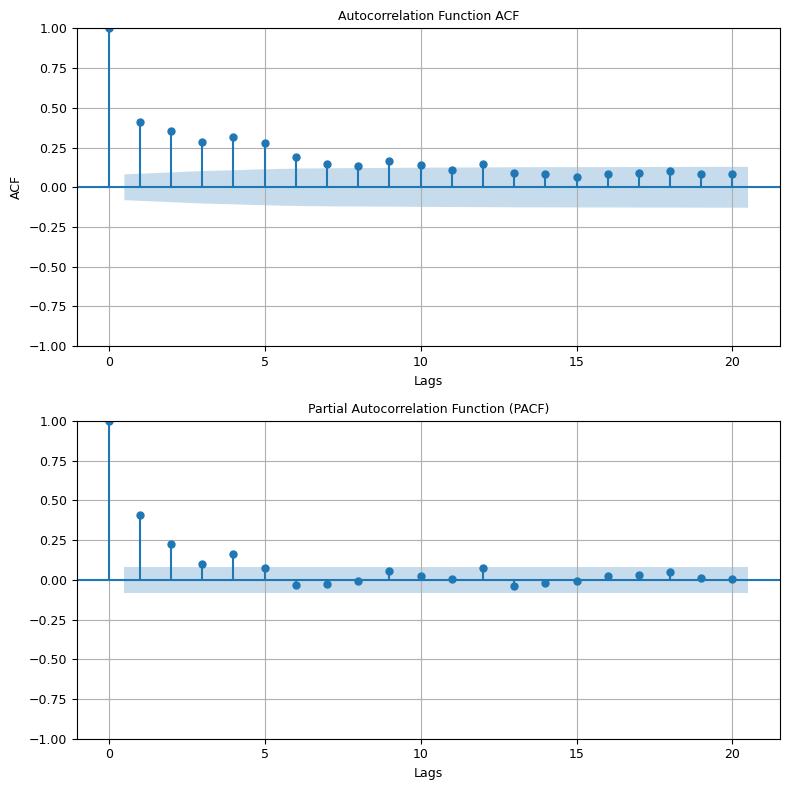

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, (ax1, ax2)=plt.subplots(2,1,figsize=(8,8))
plot_acf(cmtl["volume"], lags=20, ax=ax1)
ax1.set_title("Autocorrelation Function ACF", fontsize=9)
ax1.set_xlabel('Lags', fontsize=9)
ax1.set_ylabel('ACF', fontsize=9)
ax1.grid(True)

plot_pacf(cmtl["volume"], lags=20, ax=ax2)
ax2.set_title('Partial Autocorrelation Function (PACF)', fontsize=9)
ax2.set_xlabel('Lags', fontsize=9)
ax2.grid(True)

for ax in [ax1,ax2]:
  ax.tick_params(axis='both', labelsize=9)

plt.tight_layout()
plt.show()

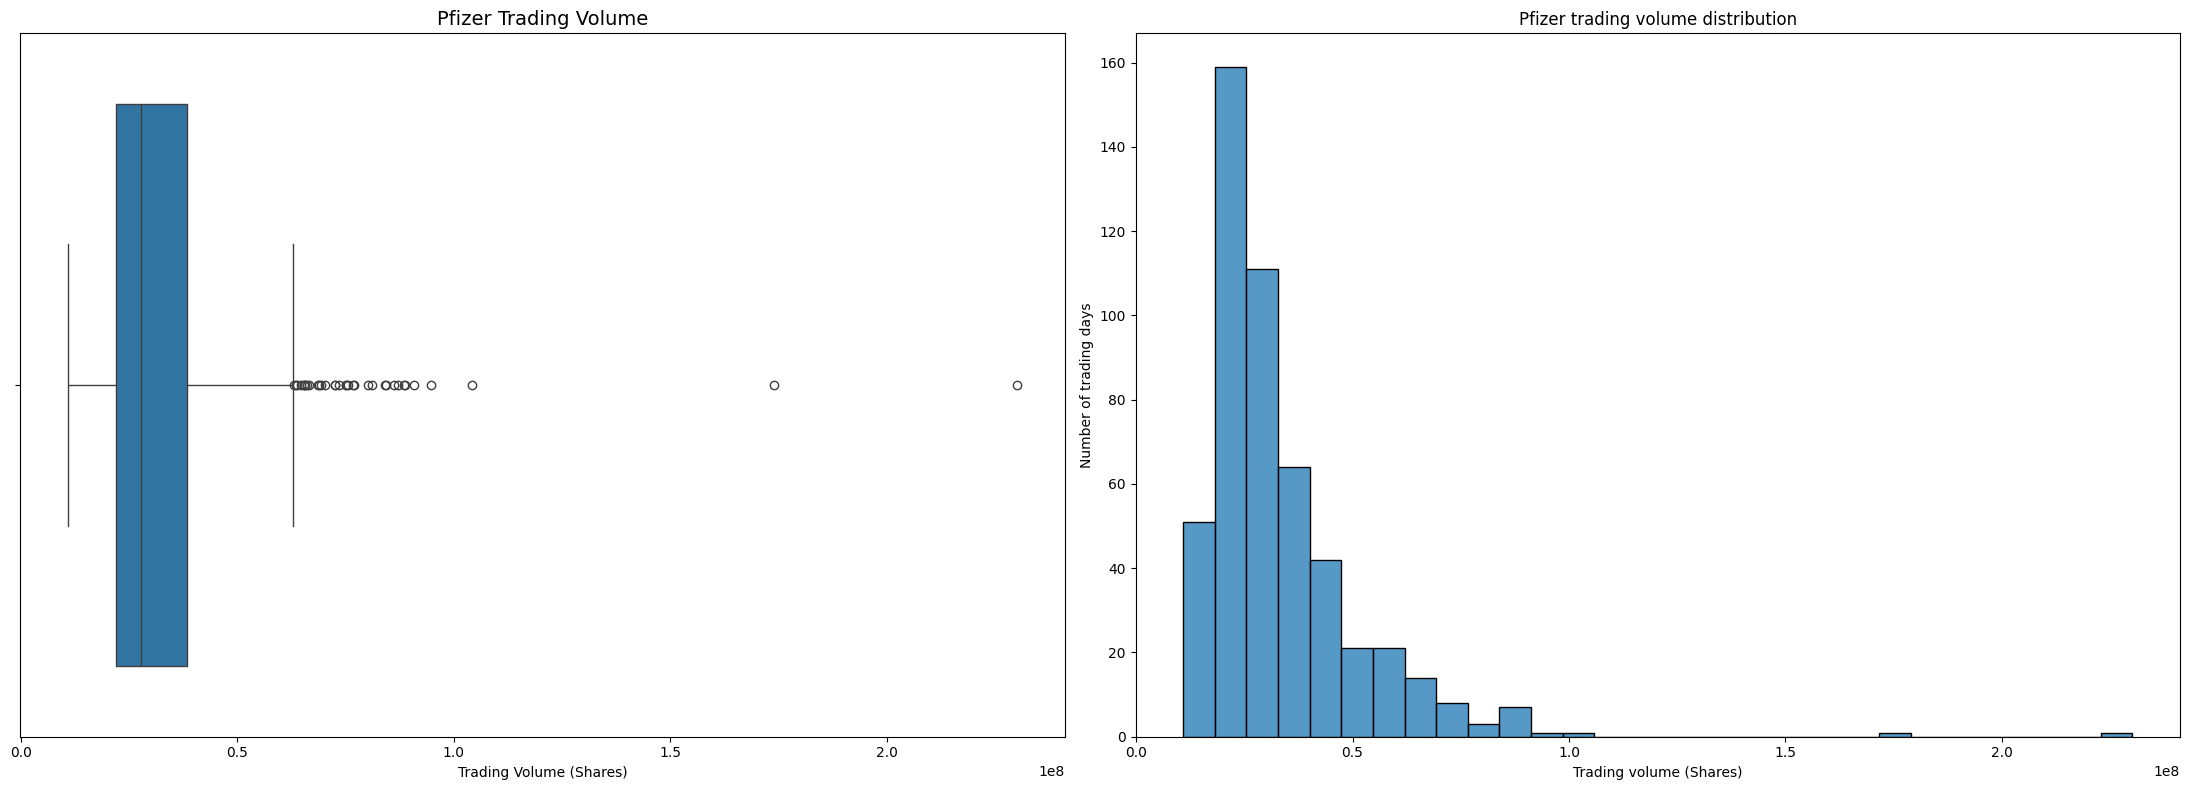

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(22,8))
sns.boxplot(
    data=pfe,
    x='volume',
    orient="h",
    ax=ax[0]
)

ax[0].set_title('Pfizer Trading Volume', fontsize='14')
ax[0].set_xlabel("Trading Volume (Shares)")

sns.histplot(
    data=pfe,
    x="volume",
    bins=30,
    ax=ax[1]
)

ax[1].set_title('Pfizer trading volume distribution')
ax[1].set_xlabel("Trading volume (Shares)")
ax[1].set_ylabel("Number of trading days")
plt.tight_layout()
plt.show()

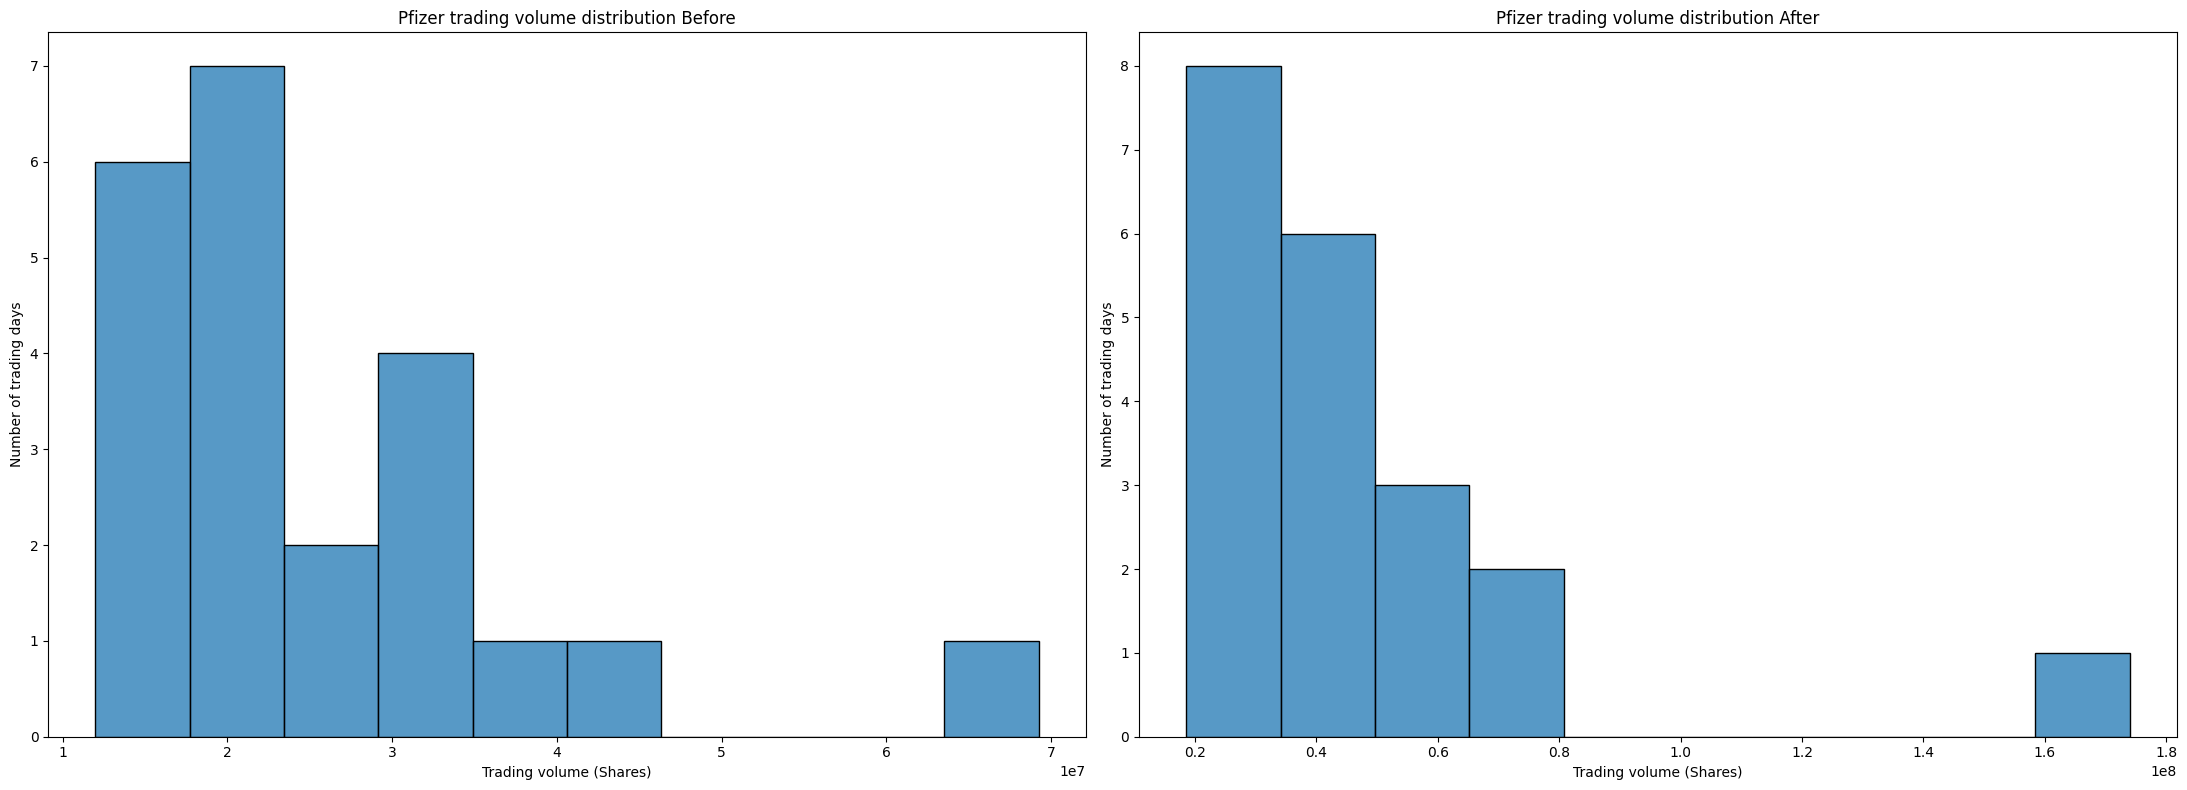

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(22,8))

df_filter1_pfe= pfe.loc["2021-10-06" : "2021-11-04"]
df_filter2_pfe=pfe.loc["2021-11-05":"2021-12-03"]
sns.histplot(
    data=df_filter1_pfe,
    x="volume",
    bins=10,
    ax=ax[0]
)

ax[0].set_title('Pfizer trading volume distribution Before')
ax[0].set_xlabel("Trading volume (Shares)")
ax[0].set_ylabel("Number of trading days")


sns.histplot(
    data=df_filter2_pfe,
    x="volume",
    bins=10,
    ax=ax[1]
)

ax[1].set_title('Pfizer trading volume distribution After')
ax[1].set_xlabel("Trading volume (Shares)")
ax[1].set_ylabel("Number of trading days")

plt.tight_layout()
plt.show()

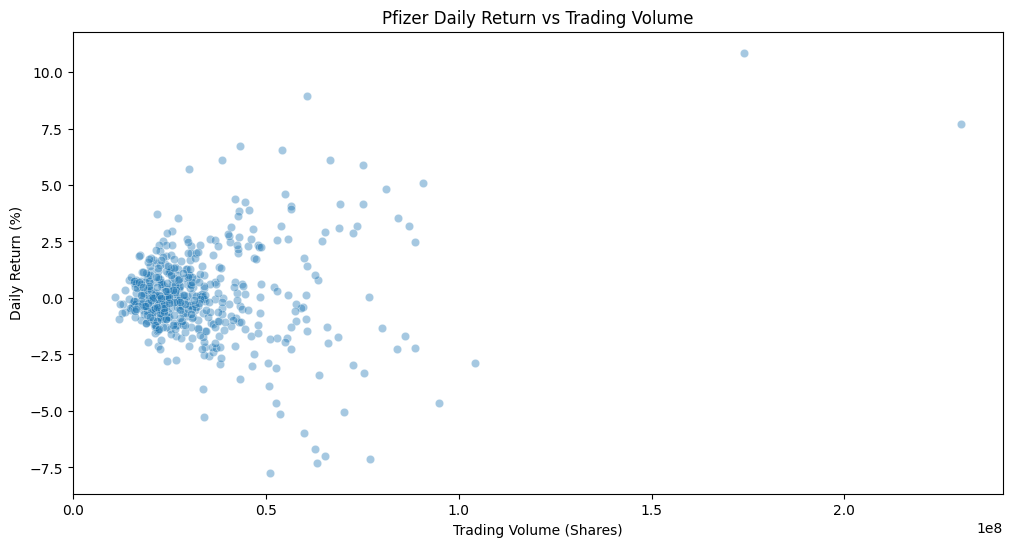

In [ ]:
plt.figure(figsize=(12,6))
sns.scatterplot(
    data=pfe,
    x="volume",
    y="daily_return",
    alpha=0.4,
)
plt.title("Pfizer Daily Return vs Trading Volume")
plt.xlabel("Trading Volume (Shares)")
plt.ylabel("Daily Return (%)")
plt.show()

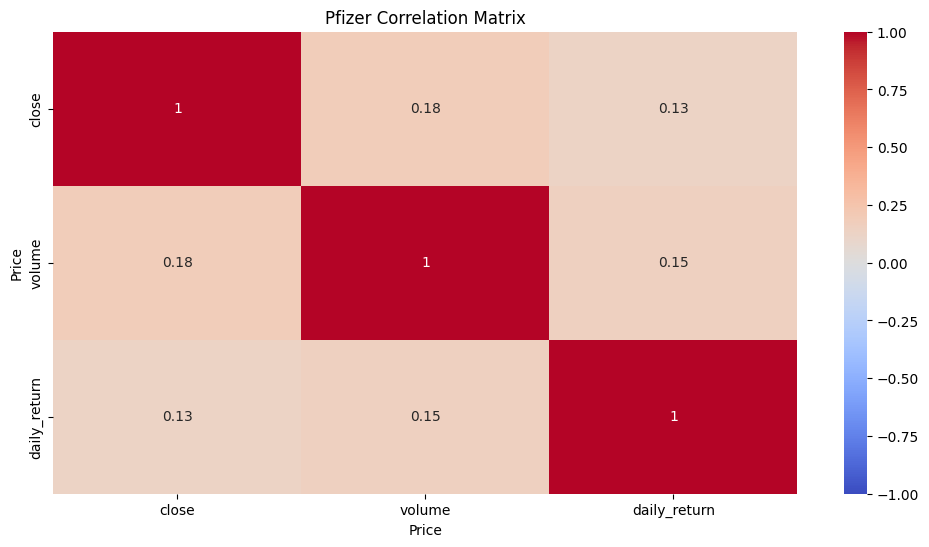

In [ ]:
plt.figure(figsize=(12,6))

corr_matrix=pfe[["close", "volume", "daily_return"]].corr()
pfe_heatmap=sns.heatmap(
    data=corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Pfizer Correlation Matrix")
plt.show()

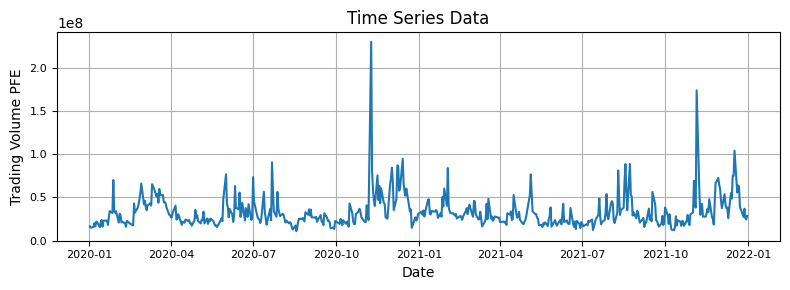

In [ ]:
plt.figure(figsize=(8,3))
plt.plot(pfe.index,pfe["volume"])
plt.xlabel('Date', fontsize=10)
plt.ylabel('Trading Volume PFE', fontsize=10)
plt.title('Time Series Data', fontsize=12)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.show()

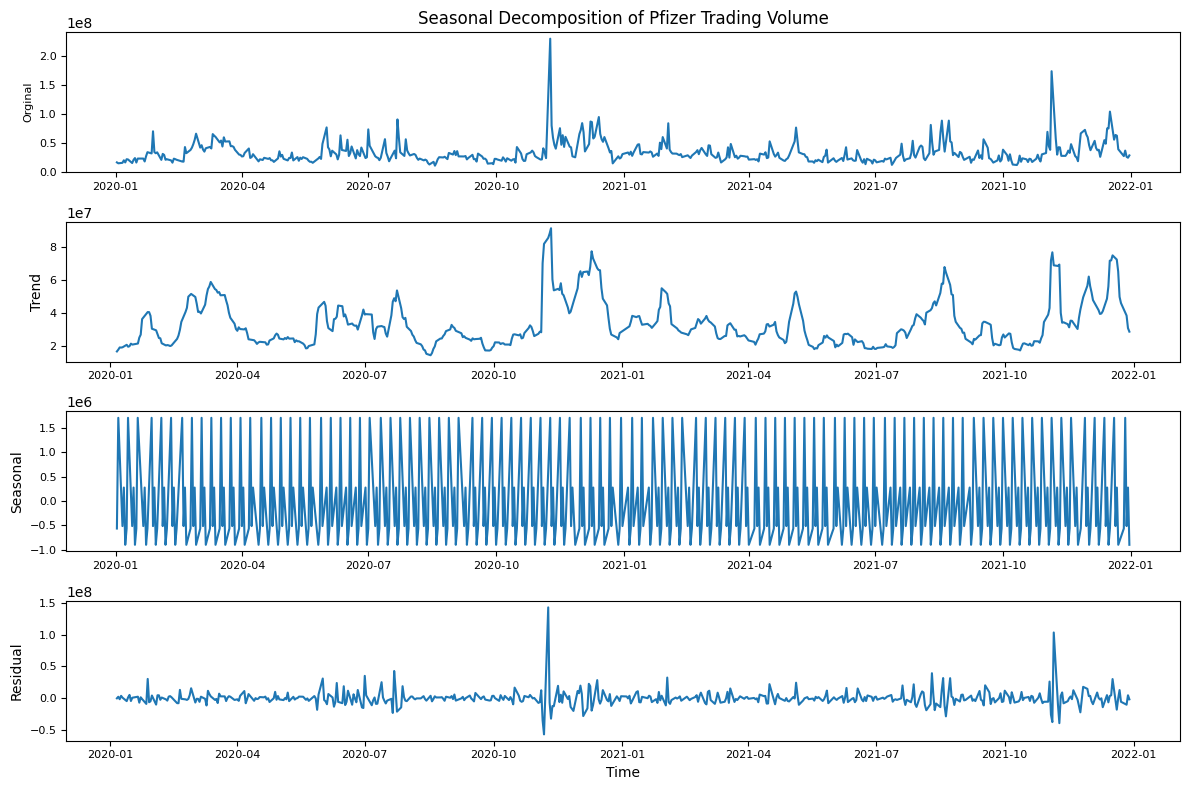

In [ ]:
result_pfe=seasonal_decompose(pfe["volume"], model="additive", period=5)
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4,1, figsize=(12,8))

ax1.plot(pfe["volume"])
ax1.set_ylabel('Orginal', fontsize=8)
ax1.set_title('Seasonal Decomposition of Pfizer Trading Volume', fontsize=12)

ax2.plot(result_pfe.trend)
ax2.set_ylabel('Trend', fontsize=10)

ax3.plot(result_pfe.seasonal)
ax3.set_ylabel('Seasonal', fontsize=10)

ax4.plot(result_pfe.resid)
ax4.set_xlabel('Time', fontsize=10)
ax4.set_ylabel('Residual', fontsize=10)

for ax in [ax1, ax2, ax3, ax4]:
  ax.tick_params(axis='both', labelsize=8)

plt.tight_layout()
plt.show()

0


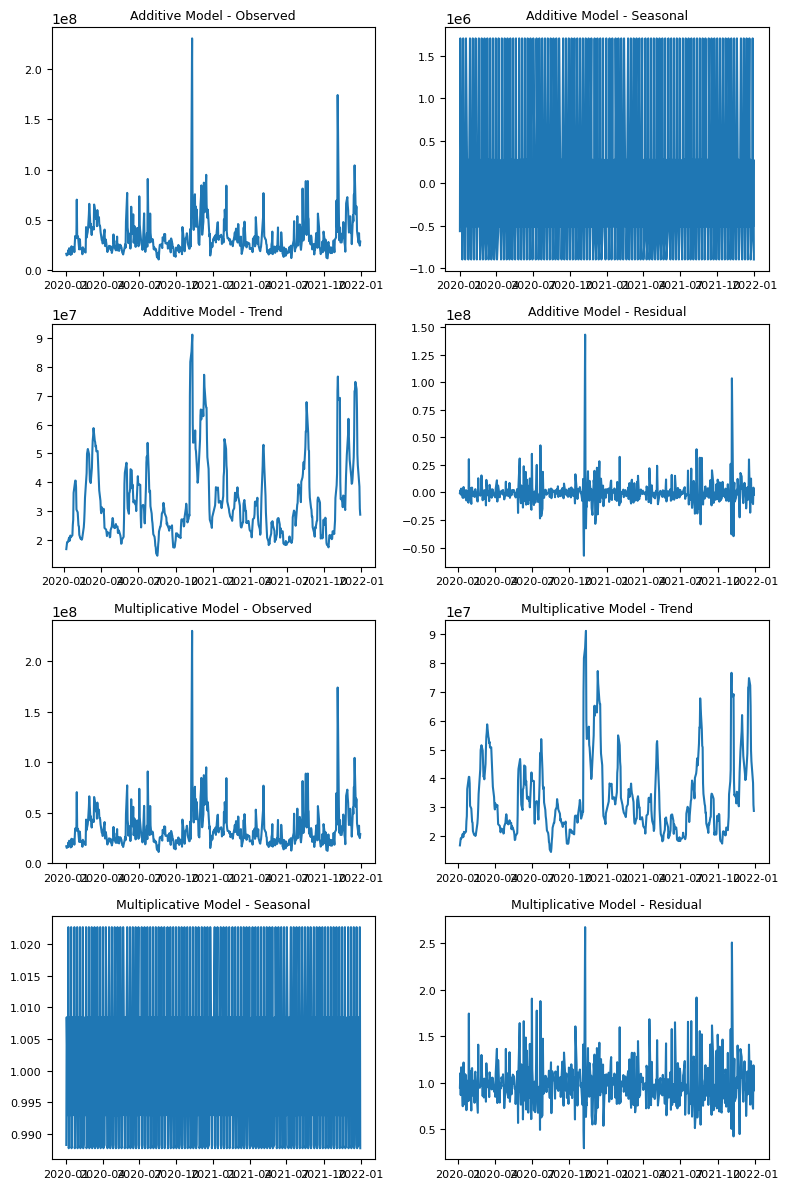

In [ ]:
result_add_pfe=seasonal_decompose(pfe["volume"], model='additive', period=5)
print((pfe["volume"]<=0).sum())
result_mul_pfe=seasonal_decompose(pfe["volume"], model='multiplicative', period=5)

fig,axes=plt.subplots(4,2,figsize=(8,12))

axes[0,0].plot(result_add_pfe.observed)
axes[0,0].set_title('Additive Model - Observed', fontsize=9)

axes[1,0].plot(result_add_pfe.trend)
axes[1,0].set_title('Additive Model - Trend', fontsize=9)

axes[0,1].plot(result_add_pfe.seasonal)
axes[0,1].set_title('Additive Model - Seasonal', fontsize=9)

axes[1,1].plot(result_add_pfe.resid)
axes[1,1].set_title('Additive Model - Residual', fontsize=9)

axes[2,0].plot(result_mul_pfe.observed)
axes[2,0].set_title('Multiplicative Model - Observed', fontsize=9)

axes[2,1].plot(result_mul_pfe.trend)
axes[2,1].set_title('Multiplicative Model - Trend', fontsize=9)

axes[3,0].plot(result_mul_pfe.seasonal)
axes[3,0].set_title('Multiplicative Model - Seasonal', fontsize=9)

axes[3,1].plot(result_mul_pfe.resid)
axes[3,1].set_title('Multiplicative Model - Residual', fontsize=9)

for ax in axes.flatten():
  ax.tick_params(axis='both', labelsize=8)

plt.tight_layout()
plt.show()

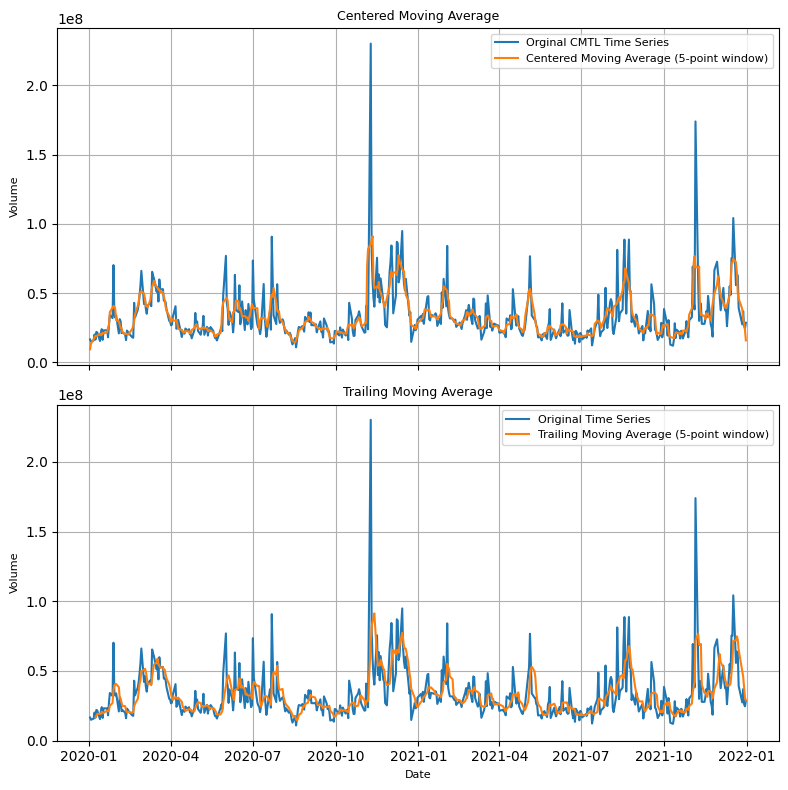

In [ ]:
centered_window_size=5
trailing_window_size=5
centered_ma_pfe=np.convolve(pfe["volume"], np.ones(centered_window_size)/centered_window_size, mode='same')
trailing_ma_pfe=np.convolve(pfe["volume"], np.ones(trailing_window_size)/trailing_window_size, mode='valid')
residual= pfe['volume']-centered_ma_pfe

fig, (ax1, ax2) = plt.subplots(2,1,figsize=(8,8), sharex=True)

ax1.plot(pfe.index, pfe["volume"], label="Orginal CMTL Time Series")
ax1.plot(pfe.index, centered_ma_pfe, label=f"Centered Moving Average ({centered_window_size}-point window)" )
ax1.set_title("Centered Moving Average", fontsize=9)
ax1.set_ylabel("Volume", fontsize=8)
ax1.legend(fontsize=8)
ax1.grid(True)

ax2.plot(pfe.index, pfe["volume"], label="Original Time Series")
ax2.plot(pfe.index[trailing_window_size-1:], trailing_ma_pfe, label=f"Trailing Moving Average ({trailing_window_size}-point window)")
ax2.set_title("Trailing Moving Average", fontsize=9)
ax2.set_ylabel("Volume", fontsize=8)
ax2.set_xlabel("Date", fontsize=8)
ax2.legend(fontsize=8)
ax2.grid(True)

plt.tight_layout()
plt.show()

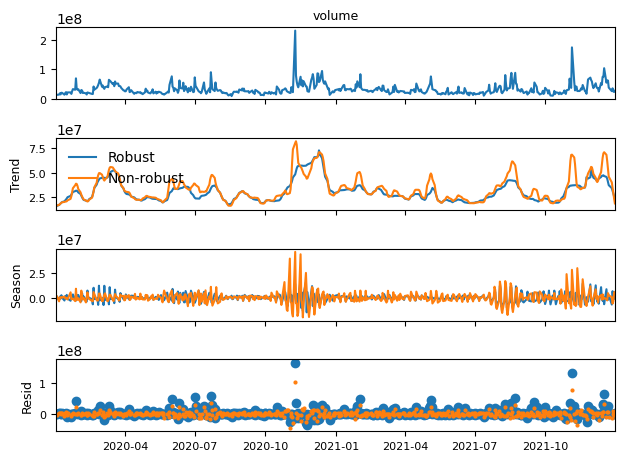

In [ ]:
def add_stl_plot(fig, res, legend):
  axs=fig.get_axes()
  comps=["trend", "seasonal", "resid"]
  for ax, comp in zip(axs[1:], comps):
    series=getattr(res,comp)
    if comp == "resid":
      ax.plot(series, marker="o", linestyle="none", markersize=2)
    else:
      ax.plot(series)
      if comp=="trend":
        ax.legend(legend, frameon=False)
stl=STL(pfe["volume"], period=5, robust=True)
res_robust=stl.fit()
fig=res_robust.plot()

for ax in fig.get_axes():
  ax.set_title(ax.get_title(), fontsize=9)
  ax.set_xlabel(ax.get_xlabel(), fontsize=9)
  ax.set_ylabel(ax.get_ylabel(), fontsize=9)
  ax.tick_params(axis='both', labelsize=8)

res_non_robust=STL(pfe["volume"], period=5, robust=False).fit()
add_stl_plot(fig, res_non_robust, ["Robust", "Non-robust"])

plt.show()

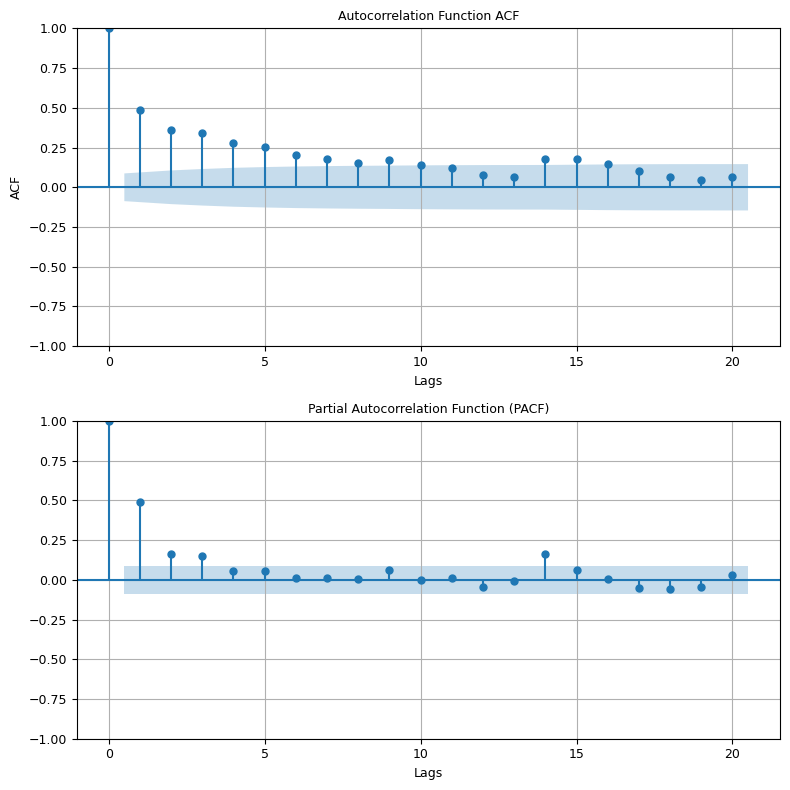

In [ ]:
fig, (ax1, ax2)=plt.subplots(2,1,figsize=(8,8))
plot_acf(pfe["volume"], lags=20, ax=ax1)
ax1.set_title("Autocorrelation Function ACF", fontsize=9)
ax1.set_xlabel('Lags', fontsize=9)
ax1.set_ylabel('ACF', fontsize=9)
ax1.grid(True)

plot_pacf(pfe["volume"], lags=20, ax=ax2)
ax2.set_title('Partial Autocorrelation Function (PACF)', fontsize=9)
ax2.set_xlabel('Lags', fontsize=9)
ax2.grid(True)

for ax in [ax1,ax2]:
  ax.tick_params(axis='both', labelsize=9)

plt.tight_layout()
plt.show()

Feature Engineering

calculate rolling average based on 20 consecutive trading observations

amount of trading volume we normally expect for a stock based on recent days


In [ ]:
#Feature engineering
#calculate rolling average based on 20 consecutive trading observations
#amount of trading volume we normally expect for a stock based on recent days
cmtl['volume_baseline']=(
    cmtl["volume"].rolling(window=20).mean().shift(1)
)
#calculate ratio between todays volume/historical average volume
cmtl['volume_ratio']=(cmtl["volume"]/cmtl["volume_baseline"])
#calculate today's volume - yesterday's volume
cmtl['volume_diff']=cmtl["volume"].diff()

In [ ]:
#Feature engineering
#calculate rolling average based on 20 consecutive trading observations
#amount of trading volume we normally expect for a stock based on recent days
pfe['volume_baseline']=(
    pfe["volume"].rolling(window=20).mean().shift(1)
)
#calculate ratio between todays volume/historical average volume
pfe['volume_ratio']=(pfe["volume"]/pfe["volume_baseline"])
#calculate today's volume - yesterday's volume
pfe['volume_diff']=pfe["volume"].diff()